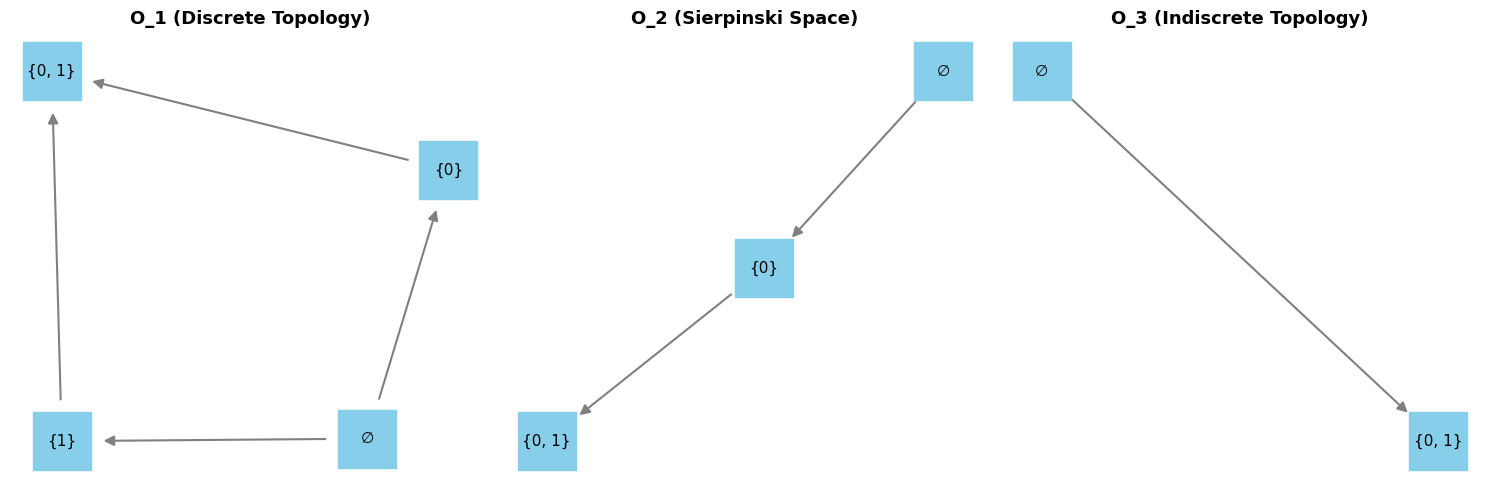

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. 画像の出力結果にある n = 2 の3つの代表元（representatives）を定義
# 1. define the three representative topologies for n = 2
# Each topology is represented as a collection of open sets (frozensets)
topologies = {
    "O_1 (Discrete Topology)": [
        frozenset(),
        frozenset({0}),
        frozenset({1}),
        frozenset({0, 1})
    ],
    "O_2 (Sierpinski Space)": [
        frozenset(),
        frozenset({0}),
        frozenset({0, 1})
    ],
    "O_3 (Indiscrete Topology)": [
        frozenset(),
        frozenset({0, 1})
    ]
}

# 2. 3つの図を並べるプロット設定
# Set up a figure with 1 row and 3 columns for the three figures
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, open_sets) in zip(axes, topologies.items()):
    # 有向グラフの初期化 (部分集合の包含関係 A ⊆ B を A -> B のエッジとして追加)
    # initialize a directed graph for the Hasse diagram
    G = nx.DiGraph()

    # グラフのノード名を見やすい文字列表現（例: "∅", "{0}", "{0, 1}"）に変換する辞書
    # create a dictionary mapping each open set to its string label for easier visualization
    node_labels = {}
    for s in open_sets:
        label = "∅" if not s else "{" + ", ".join(map(str, sorted(s))) + "}"
        node_labels[s] = label

    G.add_nodes_from(open_sets)

    # 包含関係にあるペア間にエッジを作る
    # add edges for subset relations
    for s1 in open_sets:
        for s2 in open_sets:
            if s1 != s2 and s1.issubset(s2):
                G.add_edge(s1, s2)

    # 3. 推移的簡約（Transitive Reduction）によるハッセ図化（無駄な推移エッジを削除）
    # 3. delete transitive edges to create the Hasse diagram (transitive reduction)
    H = nx.transitive_reduction(G)
    H_di = nx.DiGraph()
    H_di.add_nodes_from(G.nodes())
    H_di.add_edges_from(H.edges())

    # 4. グラフのレイアウト計算 
    # 4. layout
    try:
        # Graphviz (pygraphviz) が利用可能な場合
        pos = nx.nx_agraph.graphviz_layout(H_di, prog='dot')
    except (ImportError, Exception):
        # 例外処理で spring_layout を使用
        pos = nx.spring_layout(H_di, seed=42)

    # 5. プロットの描画
    # 5. plot
    labels_mapped = {node: node_labels[node] for node in H_di.nodes()}
    nx.draw(
        H_di, pos, ax=ax, with_labels=True, labels=labels_mapped,
        node_size=1800, node_color='skyblue', font_size=11,
        arrowsize=15, node_shape='s', edge_color='gray', width=1.5
    )
    ax.set_title(name, fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig("topology_n2.png", bbox_inches='tight') # この行を追加して画像を保存 save a figure
plt.show()


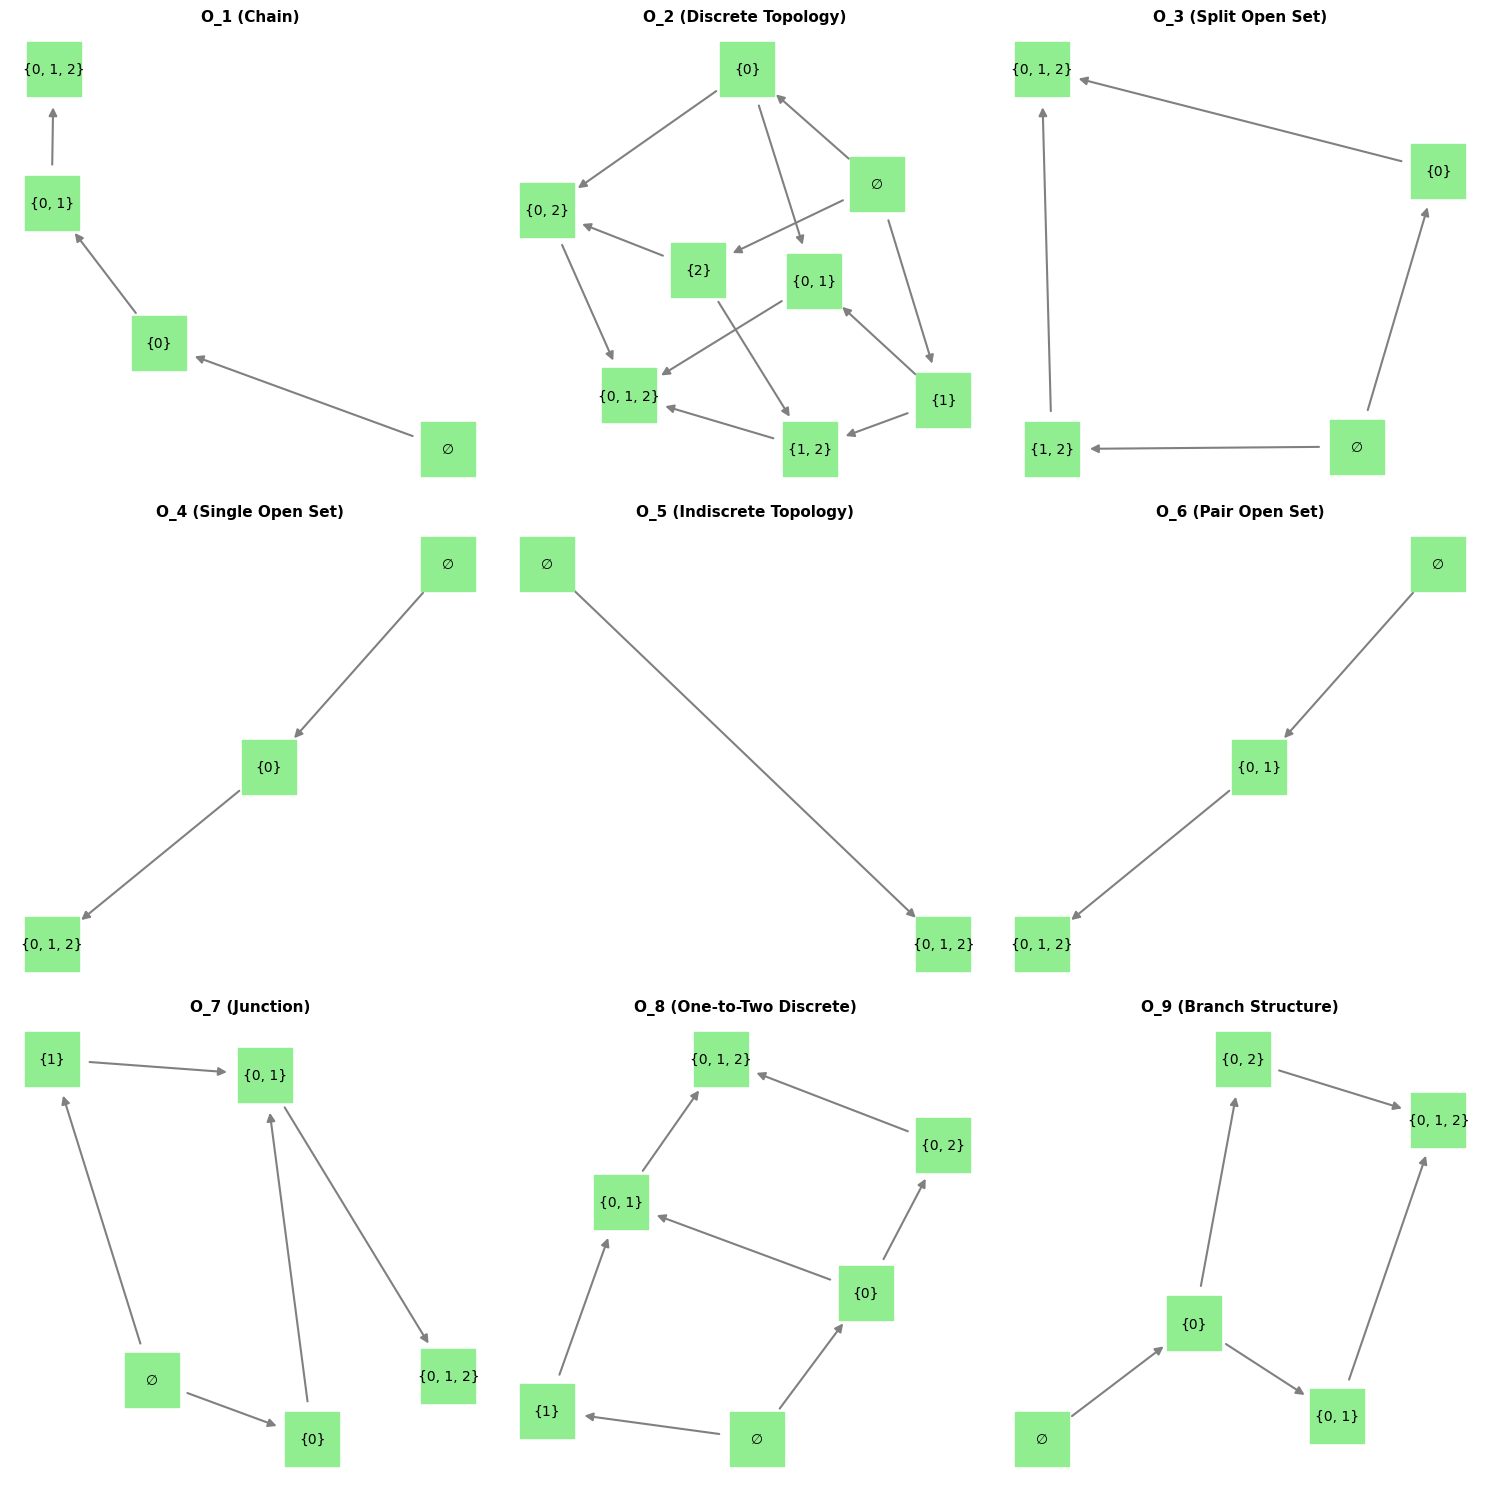

In [17]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. 画像の出力結果にある n = 3 の9つの代表元（representatives）を定義
# 1. define the nine representative topologies for n = 3
# Each topology is represented as a collection of open sets (frozensets)

topologies_n3 = {
    "O_1 (Chain)": [
        frozenset(), frozenset({0}), frozenset({0, 1}), frozenset({0, 1, 2})
    ],
    "O_2 (Discrete Topology)": [
        frozenset(), frozenset({0}), frozenset({1}), frozenset({2}),
        frozenset({0, 1}), frozenset({0, 2}), frozenset({1, 2}), frozenset({0, 1, 2})
    ],
    "O_3 (Split Open Set)": [
        frozenset(), frozenset({0}), frozenset({1, 2}), frozenset({0, 1, 2})
    ],
    "O_4 (Single Open Set)": [
        frozenset(), frozenset({0}), frozenset({0, 1, 2})
    ],
    "O_5 (Indiscrete Topology)": [
        frozenset(), frozenset({0, 1, 2})
    ],
    "O_6 (Pair Open Set)": [
        frozenset(), frozenset({0, 1}), frozenset({0, 1, 2})
    ],
    "O_7 (Junction)": [
        frozenset(), frozenset({0}), frozenset({1}), frozenset({0, 1}), frozenset({0, 1, 2})
    ],
    "O_8 (One-to-Two Discrete)": [
        frozenset(), frozenset({0}), frozenset({1}), frozenset({0, 1}), frozenset({0, 2}), frozenset({0, 1, 2})
    ],
    "O_9 (Branch Structure)": [
        frozenset(), frozenset({0}), frozenset({0, 1}), frozenset({0, 2}), frozenset({0, 1, 2})
    ]
}

# 2. 3x3 のグリッドで 9 つのトポロジーを描画する設定
# Set up a figure with 3 rows and 3 columns for the nine figures
    
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

for ax, (name, open_sets) in zip(axes, topologies_n3.items()):
    # 有向グラフの初期化 (包含関係 A ⊆ B を A -> B のエッジとして追加)
    # initialize a directed graph for the Hasse diagram
    G = nx.DiGraph()

    # ノード名を見やすい数学的表記（例: "∅", "{0}", "{0, 1, 2}"）に変換する辞書
    # create a dictionary mapping each open set to its string label for easier visualization
    node_labels = {}
    for s in open_sets:
        label = "∅" if not s else "{" + ", ".join(map(str, sorted(s))) + "}"
        node_labels[s] = label

    G.add_nodes_from(open_sets)

    # 包含関係にあるペア間にエッジを張る
    # add edges for subset relations
    for s1 in open_sets:
        for s2 in open_sets:
            if s1 != s2 and s1.issubset(s2):
                G.add_edge(s1, s2)

    # 3. 推移的簡約（Transitive Reduction）によるハッセ図化（無駄な推移エッジを削除）
    # 3. delete transitive edges to create the Hasse diagram (transitive reduction)
    H = nx.transitive_reduction(G)
    H_di = nx.DiGraph()
    H_di.add_nodes_from(G.nodes())
    H_di.add_edges_from(H.edges())

    # 4. グラフのレイアウト計算（階層構造が分かりやすいように配置）
    # 4. layout
    try:
        pos = nx.nx_agraph.graphviz_layout(H_di, prog='dot')
    except (ImportError, Exception):
        pos = nx.spring_layout(H_di, seed=42)

    # 5. プロットの描画
    # 5. plot
    labels_mapped = {node: node_labels[node] for node in H_di.nodes()}
    nx.draw(
        H_di, pos, ax=ax, with_labels=True, labels=labels_mapped,
        node_size=1500, node_color='lightgreen', font_size=10,
        arrowsize=12, node_shape='s', edge_color='gray', width=1.5
    )
    ax.set_title(name, fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig("topology_n3.png", bbox_inches='tight') # この行を追加して画像を保存 save a figure
plt.show()

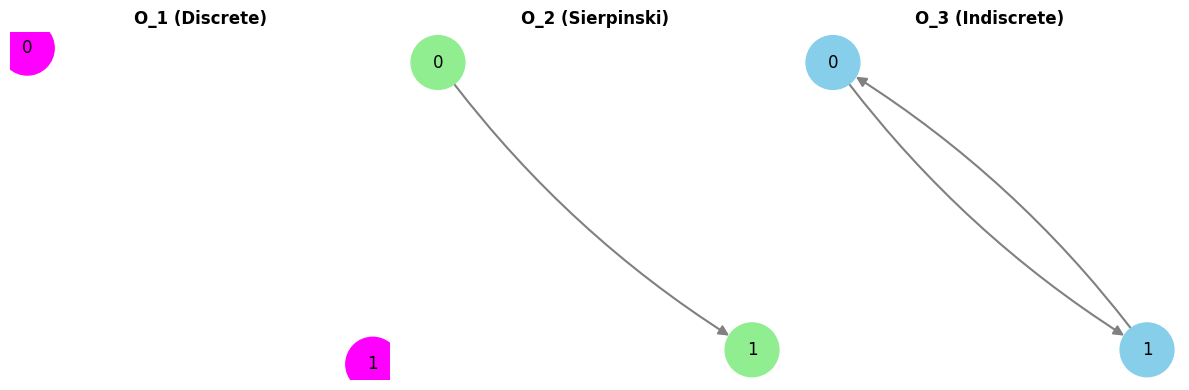

In [8]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. n = 2 の3つの代表元
# 1. define the three representative topologies for n = 2
topologies_n2 = {
    "O_1 (Discrete)": [
        frozenset(), frozenset({0}), frozenset({1}), frozenset({0, 1})
    ],
    "O_2 (Sierpinski)": [
        frozenset(), frozenset({0}), frozenset({0, 1})
    ],
    "O_3 (Indiscrete)": [
        frozenset(), frozenset({0, 1})
    ]
}

universe = {0, 1}
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (name, open_sets) in zip(axes, topologies_n2.items()):
    # 2. 各点 x に対する最小の開集合を求める
    # 2. find the smallest open set containing each point
    min_neighborhoods = {}
    for x in universe:
        containing_opens = [s for s in open_sets if x in s]
        res = containing_opens[0]
        for s in containing_opens[1:]:
            res = res.intersection(s)
        min_neighborhoods[x] = res

    # 3. 順序関係 a ≤ b (a ∈ U(b)) に基づいて有向グラフを作る
    # 3. create a directed graph according to the order relation a ≤ b (a ∈ U(b))
    G = nx.DiGraph()
    G.add_nodes_from(universe)

    for a in universe:
        for b in universe:
            if a in min_neighborhoods[b]:
                if a != b:  # 自己ループを除外
                    G.add_edge(a, b)

    # ※ transitive_reduction は DAG（非巡回）を要求するため、前順序集合を起こす。
    # 4. 双方向のエッジを含んだまま描画用にセット
    # 4. set up a graph including the bidirectional edges for visualization
    H_di = G
    
  # === 変更箇所: 双方向と孤立ノードの判定を組み合わせて色分け ===
    bidirectional_nodes = set()
    for u, v in H_di.edges():
        if H_di.has_edge(v, u):
            bidirectional_nodes.add(u)
            bidirectional_nodes.add(v)

    node_colors = []
    for n in H_di.nodes():
        if n in bidirectional_nodes:
            node_colors.append('skyblue')       # 双方向エッジを持つ
        elif H_di.degree(n) == 0:
            node_colors.append('magenta')         # エッジが0本（孤立）
        else:
            node_colors.append('lightgreen')      # それ以外（1本以上のエッジ）
    # ========================================================= # =========================================================

    # 5. 描画（双方向エッジが見やすいように connectionstyle を指定）
    # plot the graph
    try:
        pos = nx.nx_agraph.graphviz_layout(H_di, prog='dot')
    except (ImportError, Exception):
        pos = nx.spring_layout(H_di, seed=42)

    nx.draw(
        H_di, pos, ax=ax, with_labels=True,
        node_size=1500, node_color=node_colors, font_size=12,
        arrowsize=15, edge_color='gray', width=1.5,
        connectionstyle='arc3, rad=0.1'  # 互いの矢印が重ならないように曲げる
    )
    ax.set_title(name, fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig("topology_n2_order.png", bbox_inches='tight') # この行を追加して画像を保存 save a figure
plt.show()


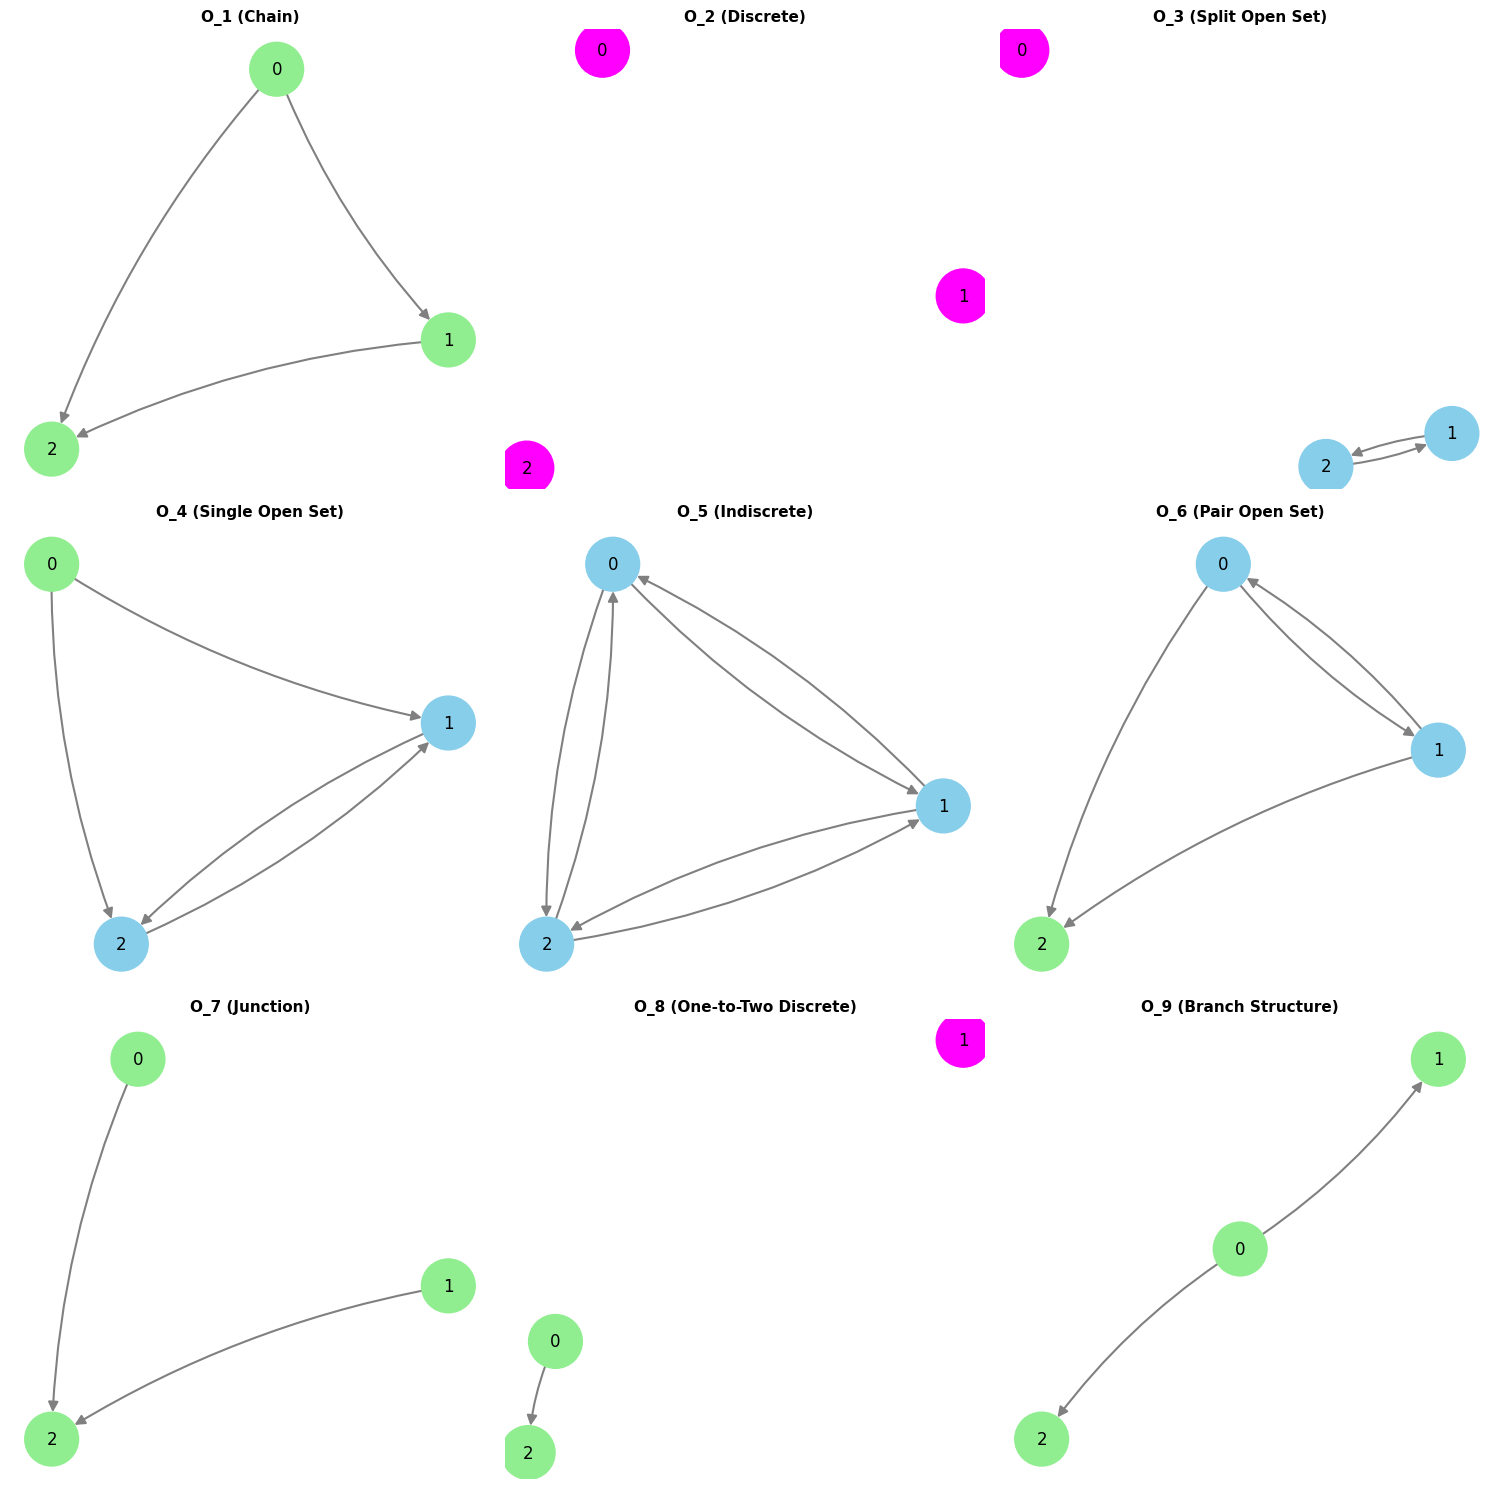

In [18]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. n = 3 の9つの同型類（representatives）
# 1. define the nine representative topologies for n = 3
topologies_n3 = {
    "O_1 (Chain)": [
        frozenset(), frozenset({0}), frozenset({0, 1}), frozenset({0, 1, 2})
    ],
    "O_2 (Discrete)": [
        frozenset(), frozenset({0}), frozenset({1}), frozenset({2}),
        frozenset({0, 1}), frozenset({0, 2}), frozenset({1, 2}), frozenset({0, 1, 2})
    ],
    "O_3 (Split Open Set)": [
        frozenset(), frozenset({0}), frozenset({1, 2}), frozenset({0, 1, 2})
    ],
    "O_4 (Single Open Set)": [
        frozenset(), frozenset({0}), frozenset({0, 1, 2})
    ],
    "O_5 (Indiscrete)": [
        frozenset(), frozenset({0, 1, 2})
    ],
    "O_6 (Pair Open Set)": [
        frozenset(), frozenset({0, 1}), frozenset({0, 1, 2})
    ],
    "O_7 (Junction)": [
        frozenset(), frozenset({0}), frozenset({1}), frozenset({0, 1}), frozenset({0, 1, 2})
    ],
    "O_8 (One-to-Two Discrete)": [
        frozenset(), frozenset({0}), frozenset({1}), frozenset({0, 1}), frozenset({0, 2}), frozenset({0, 1, 2})
    ],
    "O_9 (Branch Structure)": [
        frozenset(), frozenset({0}), frozenset({0, 1}), frozenset({0, 2}), frozenset({0, 1, 2})
    ]
}

universe = {0, 1, 2}
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

for ax, (name, open_sets) in zip(axes, topologies_n3.items()):
    # 2. 各点 x に対する最小の開集合を求める
    # 2. find the smallest open set containing each point
    min_neighborhoods = {}
    for x in universe:
        containing_opens = [s for s in open_sets if x in s]
        res = containing_opens[0]
        for s in containing_opens[1:]:
            res = res.intersection(s)
        min_neighborhoods[x] = res

    # 3. 順序関係 a ≤ b (a ∈ U(b)) に基づいて有向グラフを作る
    # 3. create a directed graph according to the order relation a ≤ b (a ∈ U(b))
    G = nx.DiGraph()
    G.add_nodes_from(universe)

    for a in universe:
        for b in universe:
            if a in min_neighborhoods[b]:
                if a != b:  # 自己ループを除外
                    G.add_edge(a, b)

    # 4. 双方向のエッジを含んだまま描画用にセット
    # 4. set up a graph including the bidirectional edges for visualization
    H_di = G

  # === 変更箇所: 双方向と孤立ノードの判定を組み合わせて色分け ===
    bidirectional_nodes = set()
    for u, v in H_di.edges():
        if H_di.has_edge(v, u):
            bidirectional_nodes.add(u)
            bidirectional_nodes.add(v)

    node_colors = []
    for n in H_di.nodes():
        if n in bidirectional_nodes:
            node_colors.append('skyblue')       # 双方向エッジを持つ
        elif H_di.degree(n) == 0:
            node_colors.append('magenta')         # エッジが0本（孤立）
        else:
            node_colors.append('lightgreen')      # それ以外（1本以上のエッジ）
    # ========================================================= # =========================================================

    # 5. 描画
    # plot the graph
    try:
        pos = nx.nx_agraph.graphviz_layout(H_di, prog='dot')
    except (ImportError, Exception):
        pos = nx.spring_layout(H_di, seed=42)

    nx.draw(
        H_di, pos, ax=ax, with_labels=True,
        node_size=1500, node_color=node_colors, font_size=12,
        arrowsize=15, edge_color='gray', width=1.5,
        connectionstyle='arc3, rad=0.1'  # 双方向矢印が綺麗に分かれるように設定
    )
    ax.set_title(name, fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig("topology_n3_order.png", bbox_inches='tight') # この行を追加して画像を保存 save a figure
plt.show()


# n = 4 

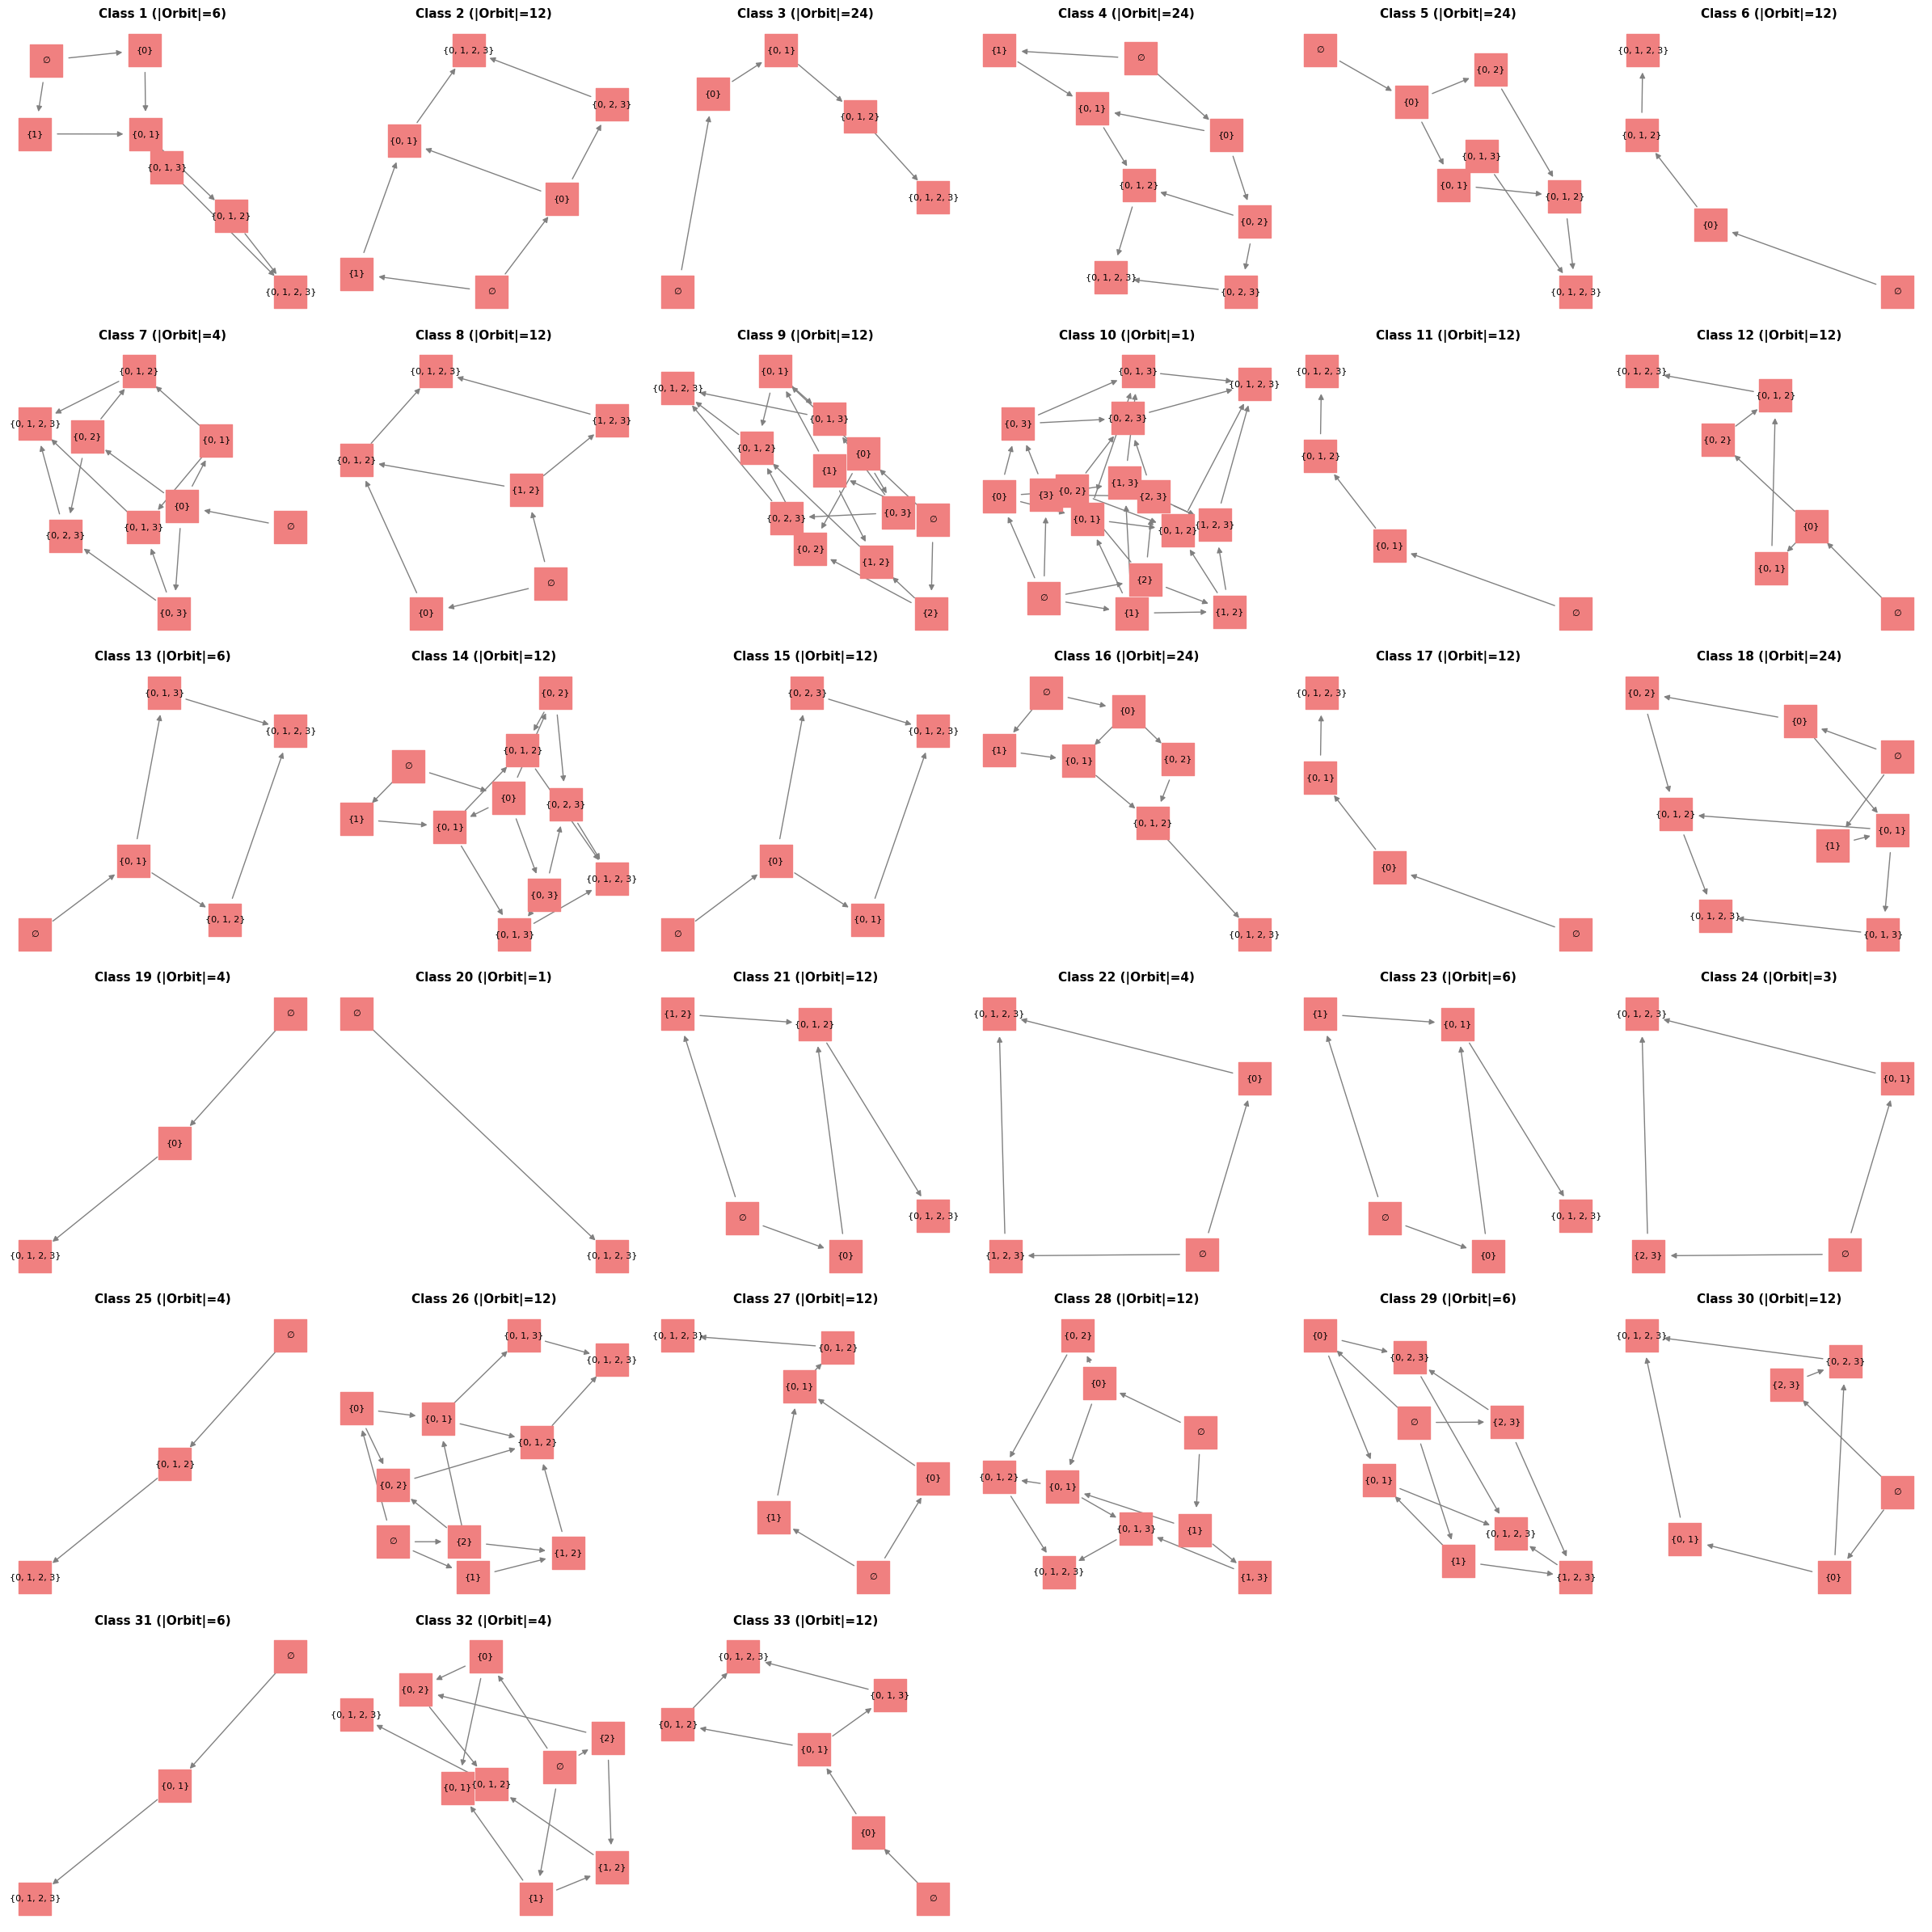

In [11]:
import json
import networkx as nx
import matplotlib.pyplot as plt
import math

# 1. JSONファイルから n=4 の位相データを読み込む
# read the JSON files and topological data
with open("topologies_n4.json", "r") as f:
    data = json.load(f)

classes = data["classes"]
num_classes = len(classes)

# 2. 33個の位相を描画するための6x6グリッドを設定
# make settings to draw the 6 by 6 grid.
grid_size = math.ceil(math.sqrt(num_classes))
fig, axes = plt.subplots(grid_size, grid_size, figsize=(24, 24))
axes = axes.flatten()

# 3. 各同型類（クラス）ごとにハッセ図を構築して描画
# depict the Hasse diagram for equivalent classes.
for idx, cls in enumerate(classes):
    ax = axes[idx]

    # JSONのリスト表現をfrozensetに変換（NetworkXのノードとして扱うため）
    # translate lists as a frozenset
    open_sets = [frozenset(s) for s in cls["topology"]]

    G = nx.DiGraph()

    # ノードラベルの作成（例: "∅", "{0, 1}"）
    # create lables of nodes
    node_labels = {}
    for s in open_sets:
        label = "∅" if not s else "{" + ", ".join(map(str, sorted(s))) + "}"
        node_labels[s] = label

    G.add_nodes_from(open_sets)

    # 包含関係 (A ⊂ B) のエッジを追加
    # add edges of inclusion relations
    for s1 in open_sets:
        for s2 in open_sets:
            if s1 != s2 and s1.issubset(s2):
                G.add_edge(s1, s2)

    # ハッセ図として描画するため、冗長な推移的エッジを削除（推移的簡約）
    # delete transitive relations
    H = nx.transitive_reduction(G)

    # グラフのレイアウト計算（Graphvizがインストールされていればdot階層レイアウト）
    # layout
    try:
        pos = nx.nx_agraph.graphviz_layout(H, prog='dot')
    except (ImportError, Exception):
        pos = nx.spring_layout(H, seed=42)

    labels_mapped = {node: node_labels[node] for node in H.nodes()}

    # グラフの描画
    # graphs
    nx.draw(
        H, pos, ax=ax, with_labels=True, labels=labels_mapped,
        node_size=800, node_color='lightcoral', font_size=8,
        arrowsize=10, node_shape='s', edge_color='gray', width=1.0
    )

    # タイトルにクラス番号とオービットサイズ（同値類のサイズ）を表示
    # Titles with the Class number and the orbit size
    ax.set_title(f"Class {cls['class_index']} (|Orbit|={cls['orbit_size']})", fontsize=11, fontweight='bold')

# 4. 余った空のサブプロット（33番目以降）を非表示にする
# make subplots invisible
for i in range(num_classes, len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.savefig("topologies_n4.png", bbox_inches='tight') # この行を追加して画像を保存 save a figure
plt.show()

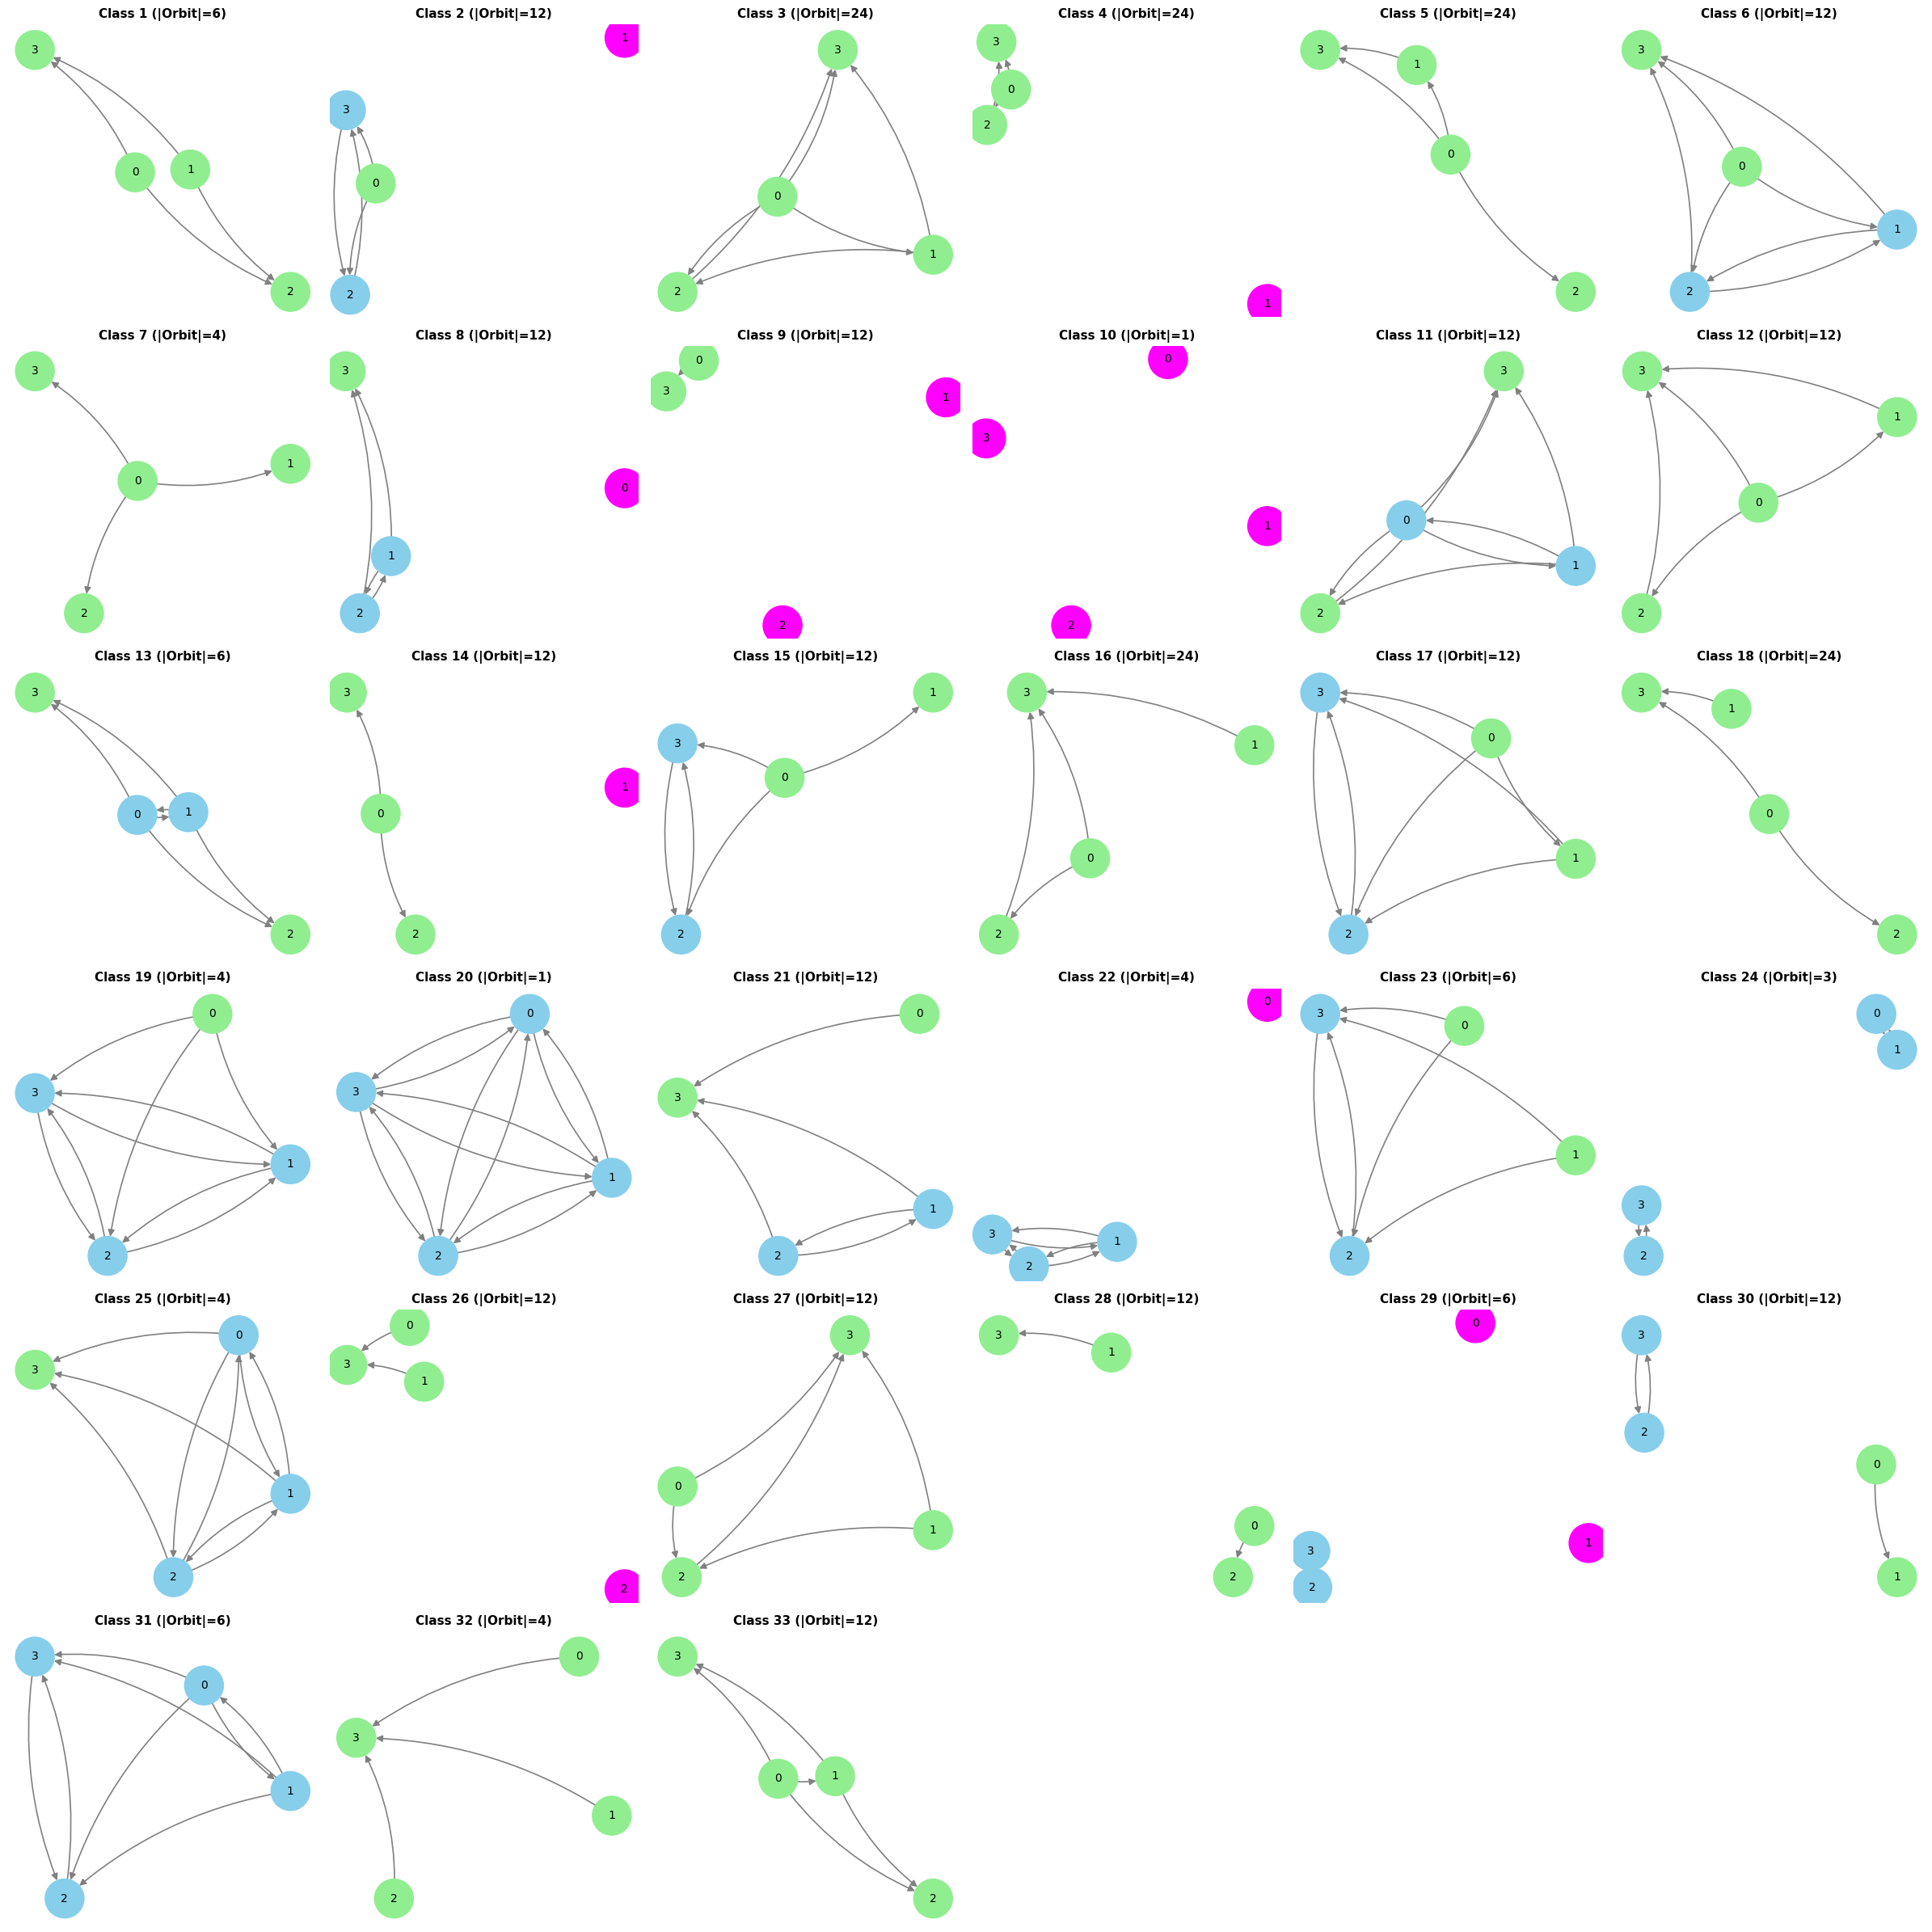

In [15]:
import json
import networkx as nx
import matplotlib.pyplot as plt
import math

# 1. Load the n=4 topologies from the JSON file
with open("topologies_n4.json", "r", encoding="utf-8") as f:
    data = json.load(f)

classes = data["classes"]
num_classes = len(classes)
universe = {0, 1, 2, 3}

# 2. Set up the 6x6 grid for the 33 classes
grid_size = math.ceil(math.sqrt(num_classes))
fig, axes = plt.subplots(grid_size, grid_size, figsize=(24, 24))
axes = axes.flatten()

# 3. Process and draw each topology
for idx, cls in enumerate(classes):
    ax = axes[idx]

    # Convert lists to frozensets for set operations
    open_sets = [frozenset(s) for s in cls["topology"]]

    # Step A: Compute the minimal neighborhood for each point x
    min_neighborhoods = {}
    for x in universe:
        containing_opens = [s for s in open_sets if x in s]
        if containing_opens:
            res = containing_opens[0]
            for s in containing_opens[1:]:
                res = res.intersection(s)
            min_neighborhoods[x] = res
        else:
            min_neighborhoods[x] = frozenset()

    # Step B: Build the directed graph based on the preorder
    # Relation a <= b means 'a' is in the minimal neighborhood of 'b'
    G = nx.DiGraph()
    G.add_nodes_from(universe)

    for a in universe:
        for b in universe:
            if a in min_neighborhoods[b]:
                if a != b:  # Exclude self-loops to keep the plot clean
                    G.add_edge(a, b)


    # === 変更箇所: 双方向と孤立ノードの判定を組み合わせて色分け ===
    bidirectional_nodes = set()
    for u, v in G.edges():
        if G.has_edge(v, u):
            bidirectional_nodes.add(u)
            bidirectional_nodes.add(v)

    node_colors = []
    for n in G.nodes():
        if n in bidirectional_nodes:
            node_colors.append('skyblue')       # 双方向エッジを持つ
        elif G.degree(n) == 0:
            node_colors.append('magenta')         # エッジが0本（孤立）
        else:
            node_colors.append('lightgreen')      # それ以外（1本以上のエッジ）
    # ========================================================= # =========================================================

    # Step C: Draw the graph
    try:
        # Use Graphviz 'dot' layout for hierarchical structure if available
        pos = nx.nx_agraph.graphviz_layout(G, prog='dot')
    except (ImportError, Exception):
        # Fallback to spring layout
        pos = nx.spring_layout(G, seed=42)

    # Draw with curved edges to reveal bidirectional relationships
    nx.draw(
        G, pos, ax=ax, with_labels=True,
        node_size=1200, node_color=node_colors, font_size=10,
        arrowsize=12, edge_color='gray', width=1.2,
        connectionstyle='arc3, rad=0.15'
    )

    # Add title with class index and orbit size
    ax.set_title(f"Class {cls['class_index']} (|Orbit|={cls['orbit_size']})", fontsize=11, fontweight='bold')

# 4. Hide any empty subplots in the 6x6 grid
for i in range(num_classes, len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.savefig("topologies_n4_order.png", bbox_inches='tight') # この行を追加して画像を保存 save a figure
plt.show()

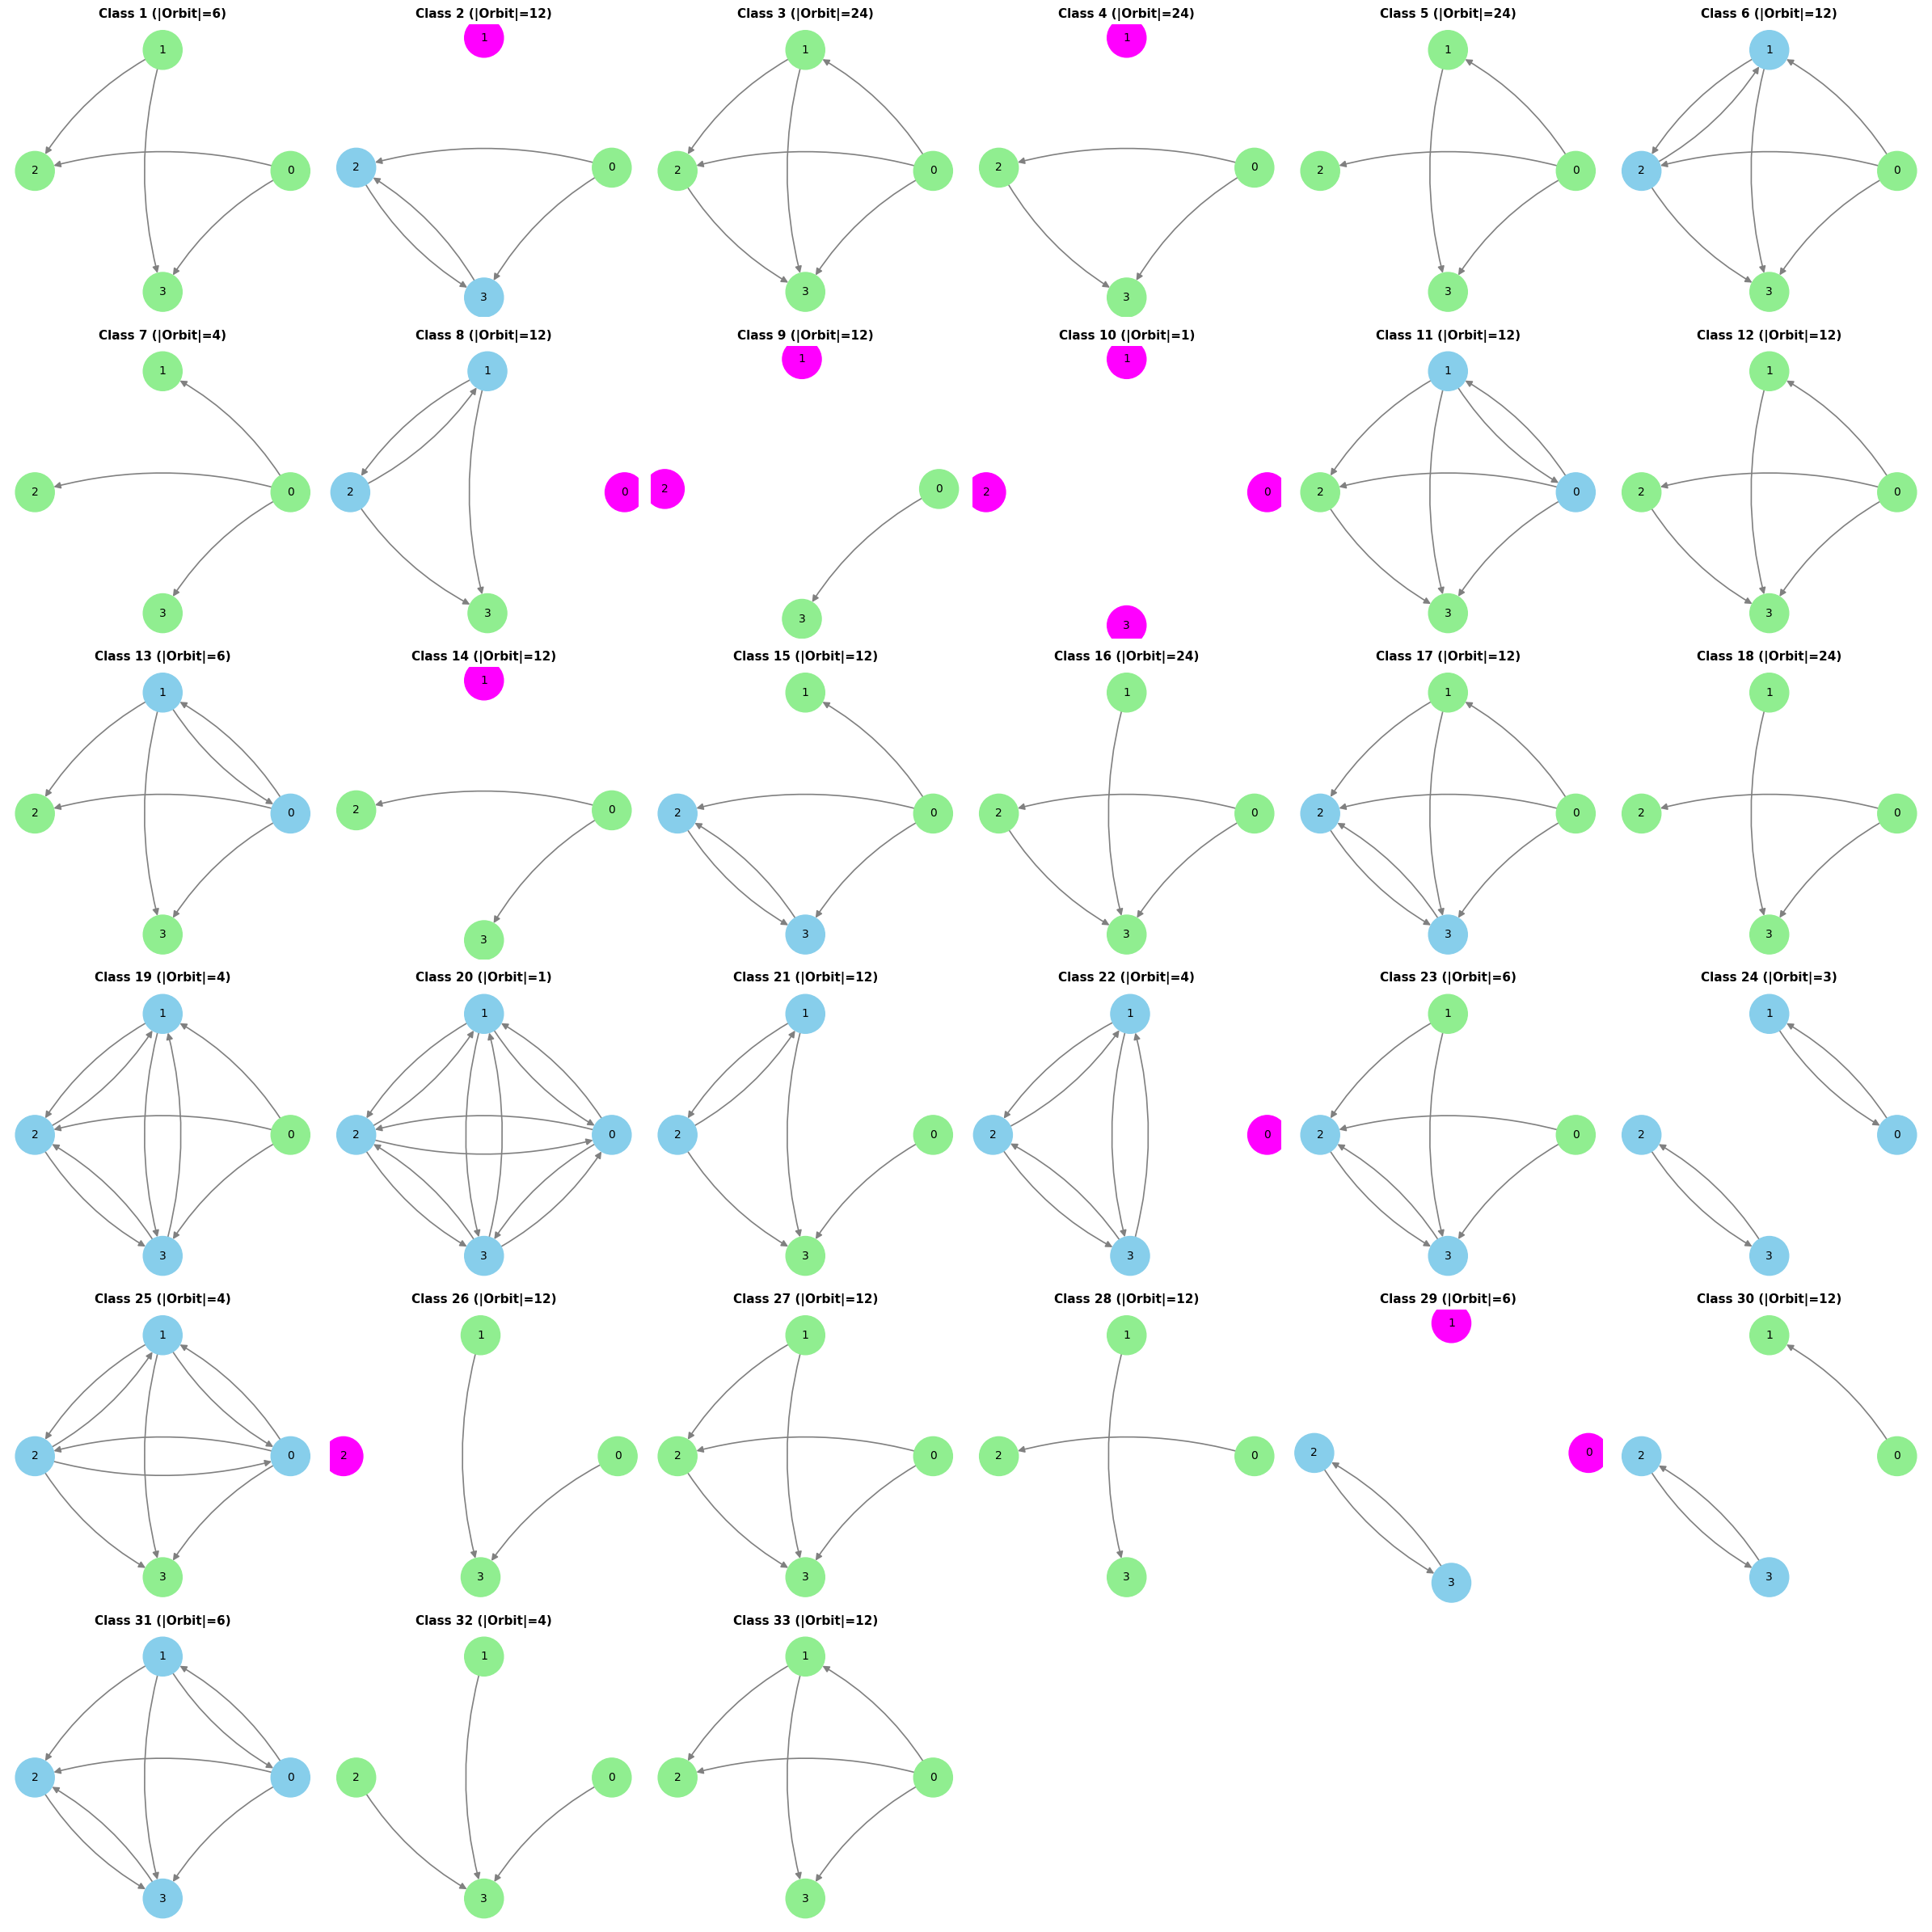

In [16]:
import json
import networkx as nx
import matplotlib.pyplot as plt
import math

with open("topologies_n4.json", "r", encoding="utf-8") as f:
    data = json.load(f)

classes = data["classes"]
num_classes = len(classes)
universe = {0, 1, 2, 3}

grid_size = math.ceil(math.sqrt(num_classes))
fig, axes = plt.subplots(grid_size, grid_size, figsize=(24, 24))
axes = axes.flatten()

for idx, cls in enumerate(classes):
    ax = axes[idx]
    open_sets = [frozenset(s) for s in cls["topology"]]

    # 最小開集合の計算
    # minimum open neighborhood set
    min_neighborhoods = {}
    for x in universe:
        containing_opens = [s for s in open_sets if x in s]
        if containing_opens:
            res = containing_opens[0]
            for s in containing_opens[1:]:
                res = res.intersection(s)
            min_neighborhoods[x] = res
        else:
            min_neighborhoods[x] = frozenset()

    # 有向グラフの構築
    # construct the directed graphs.
    G = nx.DiGraph()
    G.add_nodes_from(universe)

    for a in universe:
        for b in universe:
            if a in min_neighborhoods[b] and a != b:
                G.add_edge(a, b)
    # ノードの次数（接続されているエッジの数）を判定して色を分ける
    # 1本でもエッジがあれば 'magenta'、0本（孤立）なら 'lightgreen'
    # node_colors = ['lightgreen' if G.degree(node) > 0 else 'red' for node in G.nodes()]

    # === 変更箇所: 双方向と孤立ノードの判定を組み合わせて色分け ===
    bidirectional_nodes = set()
    for u, v in G.edges():
        if G.has_edge(v, u):
            bidirectional_nodes.add(u)
            bidirectional_nodes.add(v)

    node_colors = []
    for n in G.nodes():
        if n in bidirectional_nodes:
            node_colors.append('skyblue')       # 双方向エッジを持つ
        elif G.degree(n) == 0:
            node_colors.append('magenta')         # エッジが0本（孤立）
        else:
            node_colors.append('lightgreen')      # それ以外（1本以上のエッジ）
    # ========================================================= # =========================================================

    # 重なりを防ぐため、ノードを円状に配置する circular_layout を使用
    # use the circular_layout to avoid overlapping
    pos = nx.circular_layout(G)

    nx.draw(
        G, pos, ax=ax, with_labels=True,
        node_size=1200, node_color=node_colors, font_size=10,
        arrowsize=12, edge_color='gray', width=1.2,
        connectionstyle='arc3, rad=0.15'
    )

    ax.set_title(f"Class {cls['class_index']} (|Orbit|={cls['orbit_size']})", fontsize=11, fontweight='bold')

# make sets from num_classes to the max length invisible
for i in range(num_classes, len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.savefig("topologies_n4_order_circle.png", bbox_inches='tight') # この行を追加して画像を保存 save a figure
plt.show()